# Project Cupid
# end to end Machine Learning Pipeline for Relationship Compatibility & Longevity prediction

# Objectives
This project builds an end-to-end machine learning pipeline to:

1. Predict Relationship Success using classification.
2. Predict Compatibility score using Regression.
3. Clean and preprocess messy relationship-profile data.
4. Perfrom feature engineering, encoding, and standardization.
5. Apply feature selection and startfied K-fold cross-Validation.
6. Tune and compare baseline and ensemble machine learning models.
7. Recommend the best-performing model based on evaluation results.


In [ ]:
# ============================================================
# PROJECT CUPID - LIBRARY IMPORTS
# ============================================================

# Data Handling
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt

# Data Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Train-Test Split & Cross Validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

# Feature Selection
from sklearn.feature_selection import RFE

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# Regression Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# General Settings
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


# Module 1: Data Exploration, Wrangling and cleaning

This module focuses on creating and inspecting the raw relationship-profile dataset, identifiying missing values, handling numerical and categorical null values, detecting unrealistic outlines using the IQR method, and performing intial exploratory data analysis.


In [6]:
# ============================================================
# CREATE SYNTHETIC RAW RELATIONSHIP DATASET
# ============================================================

np.random.seed(42)

n_profiles = 600

data = {
    "Age": np.random.randint(18, 46, n_profiles),

    "Monthly_Income": np.random.normal(
        loc=60000,
        scale=25000,
        size=n_profiles
    ),

    "Communication_Score": np.random.randint(
        1, 11, n_profiles
    ),

    "Trust_Score": np.random.randint(
        1, 11, n_profiles
    ),

    "Shared_Interests": np.random.randint(
        1, 11, n_profiles
    ),

    "Red_Flags": np.random.randint(
        0, 6, n_profiles
    ),

    "Relationship_Duration_Months": np.random.randint(
        1, 61, n_profiles
    ),

    "Zodiac_Sign": np.random.choice(
        [
            "Aries", "Taurus", "Gemini", "Cancer",
            "Leo", "Virgo", "Libra", "Scorpio",
            "Sagittarius", "Capricorn",
            "Aquarius", "Pisces"
        ],
        n_profiles
    ),

    "Relationship_Success": np.random.choice(
        [0, 1],
        n_profiles,
        p=[0.40, 0.60]
    ),

    "Compatibility_Score": np.random.randint(
        10, 101, n_profiles
    )
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset created successfully!
Dataset Shape: (600, 10)


,Age,Monthly_Income,Communication_Score,Trust_Score,Shared_Interests,Red_Flags,Relationship_Duration_Months,Zodiac_Sign,Relationship_Success,Compatibility_Score
0,24,84315.821672,1,10,2,3,55,Leo,1,13
1,37,98611.870968,10,7,3,0,31,Libra,1,26
2,32,68601.703285,3,4,7,0,42,Scorpio,0,13
3,28,83155.813572,2,8,6,3,10,Capricorn,1,52
4,25,75195.963508,2,5,8,2,32,Aries,1,99


In [7]:
# ============================================================
# INTRODUCE MISSING VALUES AND DATA ANOMALIES
# ============================================================

# Add missing numerical values
missing_income = np.random.choice(
    df.index,
    size=30,
    replace=False
)

df.loc[missing_income, "Monthly_Income"] = np.nan


# Add missing Red_Flags values
missing_red_flags = np.random.choice(
    df.index,
    size=20,
    replace=False
)

df.loc[missing_red_flags, "Red_Flags"] = np.nan


# Add missing categorical Zodiac values
missing_zodiac = np.random.choice(
    df.index,
    size=25,
    replace=False
)

df.loc[missing_zodiac, "Zodiac_Sign"] = np.nan


# Add unrealistic income values / data-entry errors
outlier_indices = np.random.choice(
    df.index,
    size=8,
    replace=False
)

df.loc[outlier_indices, "Monthly_Income"] = [
    10000000,
    8500000,
    9000000,
    12000000,
    7500000,
    11000000,
    9500000,
    13000000
]


print("Missing values and income anomalies introduced successfully!")

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

Missing values and income anomalies introduced successfully!

Missing Values:
Age                              0
Monthly_Income                  30
Communication_Score              0
Trust_Score                      0
Shared_Interests                 0
Red_Flags                       20
Relationship_Duration_Months     0
Zodiac_Sign                     25
Relationship_Success             0
Compatibility_Score              0
dtype: int64

Dataset Shape: (600, 10)


In [8]:
# ============================================================
# DATA INSPECTION AND UNDERSTANDING
# ============================================================

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape:
(600, 10)

Column Names:
['Age', 'Monthly_Income', 'Communication_Score', 'Trust_Score', 'Shared_Interests', 'Red_Flags', 'Relationship_Duration_Months', 'Zodiac_Sign', 'Relationship_Success', 'Compatibility_Score']

Data Types:
Age                               int64
Monthly_Income                  float64
Communication_Score               int64
Trust_Score                       int64
Shared_Interests                  int64
Red_Flags                       float64
Relationship_Duration_Months      int64
Zodiac_Sign                      object
Relationship_Success              int64
Compatibility_Score               int64
dtype: object

Missing Values:
Age                              0
Monthly_Income                  30
Communication_Score              0
Trust_Score                      0
Shared_Interests                 0
Red_Flags                       20
Relationship_Duration_Months     0
Zodiac_Sign                     25
Relationship_Success             0
Compatibil

,Age,Monthly_Income,Communication_Score,Trust_Score,Shared_Interests,Red_Flags,Relationship_Duration_Months,Zodiac_Sign,Relationship_Success,Compatibility_Score
0,24,84315.821672,1,10,2,3.0,55,Leo,1,13
1,37,98611.870968,10,7,3,0.0,31,Libra,1,26
2,32,68601.703285,3,4,7,0.0,42,Scorpio,0,13
3,28,83155.813572,2,8,6,3.0,10,NaN,1,52
4,25,NaN,2,5,8,2.0,32,Aries,1,99


In [9]:
# ============================================================
# STATISTICAL SUMMARY
# ============================================================

print("Statistical Summary of Numerical Features:")
display(df.describe())

Statistical Summary of Numerical Features:


,Age,Monthly_Income,Communication_Score,Trust_Score,Shared_Interests,Red_Flags,Relationship_Duration_Months,Relationship_Success,Compatibility_Score
count,600.000000,5.700000e+02,600.000000,600.000000,600.000000,580.000000,600.000000,600.000000,600.000000
mean,31.806667,2.015166e+05,5.475000,5.465000,5.316667,2.501724,30.853333,0.566667,54.670000
std,8.603448,1.195409e+06,2.924659,2.807474,2.804669,1.698825,17.803842,0.495949,26.529936
min,18.000000,-2.410239e+04,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,10.000000
25%,24.000000,4.299078e+04,3.000000,3.000000,3.000000,1.000000,16.000000,0.000000,32.000000
50%,32.000000,6.208366e+04,5.000000,5.000000,5.000000,3.000000,32.000000,1.000000,54.000000
75%,39.250000,8.047868e+04,8.000000,8.000000,8.000000,4.000000,47.000000,1.000000,78.000000
max,45.000000,1.300000e+07,10.000000,10.000000,10.000000,5.000000,60.000000,1.000000,100.000000


In [10]:
# ============================================================
# TARGET VARIABLE DISTRIBUTION
# ============================================================

print("Relationship Success Distribution:")
print(df["Relationship_Success"].value_counts())

print("\nRelationship Success Percentage:")
print(
    df["Relationship_Success"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Relationship Success Distribution:
Relationship_Success
1    340
0    260
Name: count, dtype: int64

Relationship Success Percentage:
Relationship_Success
1    56.67
0    43.33
Name: proportion, dtype: float64


In [11]:
# ============================================================
# NUMERICAL NULL VALUE IMPUTATION - MEDIAN
# ============================================================

# Calculate medians
income_median = df["Monthly_Income"].median()
red_flags_median = df["Red_Flags"].median()

# Fill missing numerical values
df["Monthly_Income"] = df["Monthly_Income"].fillna(income_median)
df["Red_Flags"] = df["Red_Flags"].fillna(red_flags_median)

print("Monthly Income Median:", round(income_median, 2))
print("Red Flags Median:", red_flags_median)

print("\nMissing Numerical Values After Imputation:")
print(df[["Monthly_Income", "Red_Flags"]].isnull().sum())

Monthly Income Median: 62083.66
Red Flags Median: 3.0

Missing Numerical Values After Imputation:
Monthly_Income    0
Red_Flags         0
dtype: int64


In [12]:
# ============================================================
# CATEGORICAL NULL VALUE IMPUTATION - MODE
# ============================================================

zodiac_mode = df["Zodiac_Sign"].mode()[0]

df["Zodiac_Sign"] = df["Zodiac_Sign"].fillna(zodiac_mode)

print("Zodiac Sign Mode:", zodiac_mode)

print("\nMissing Zodiac Values After Imputation:")
print(df["Zodiac_Sign"].isnull().sum())

Zodiac Sign Mode: Scorpio

Missing Zodiac Values After Imputation:
0


In [13]:
# ============================================================
# FINAL MISSING VALUE CHECK
# ============================================================

print("Missing Values After Imputation:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values After Imputation:
Age                             0
Monthly_Income                  0
Communication_Score             0
Trust_Score                     0
Shared_Interests                0
Red_Flags                       0
Relationship_Duration_Months    0
Zodiac_Sign                     0
Relationship_Success            0
Compatibility_Score             0
dtype: int64

Total Missing Values: 0


In [14]:
# ============================================================
# IQR OUTLIER DETECTION - MONTHLY INCOME
# ============================================================

Q1 = df["Monthly_Income"].quantile(0.25)
Q3 = df["Monthly_Income"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

Q1: 43711.26
Q3: 79681.99
IQR: 35970.73
Lower Bound: -10244.83
Upper Bound: 133638.09


In [15]:
# ============================================================
# IDENTIFY INCOME OUTLIERS
# ============================================================

income_outliers = df[
    (df["Monthly_Income"] < lower_bound) |
    (df["Monthly_Income"] > upper_bound)
]

print("Number of Income Outliers:", len(income_outliers))

print("\nDetected Outliers:")
display(
    income_outliers[
        ["Age", "Monthly_Income", "Relationship_Success"]
    ].sort_values("Monthly_Income", ascending=False)
)

Number of Income Outliers: 10

Detected Outliers:


,Age,Monthly_Income,Relationship_Success
158,20,1.300000e+07,0
543,43,1.200000e+07,1
499,32,1.100000e+07,0
67,32,1.000000e+07,1
116,30,9.500000e+06,0
438,20,9.000000e+06,1
276,22,8.500000e+06,0
147,40,7.500000e+06,1
343,39,1.344049e+05,0
55,21,-2.410239e+04,0


In [16]:
# ============================================================
# REMOVE INCOME OUTLIERS
# ============================================================

rows_before = len(df)

df = df[
    (df["Monthly_Income"] >= lower_bound) &
    (df["Monthly_Income"] <= upper_bound)
].copy()

df.reset_index(drop=True, inplace=True)

rows_after = len(df)

print("Rows Before Outlier Removal:", rows_before)
print("Rows Removed:", rows_before - rows_after)
print("Rows After Outlier Removal:", rows_after)

print("\nMaximum Income After Cleaning:",
      round(df["Monthly_Income"].max(), 2))

Rows Before Outlier Removal: 600
Rows Removed: 10
Rows After Outlier Removal: 590

Maximum Income After Cleaning: 129900.82


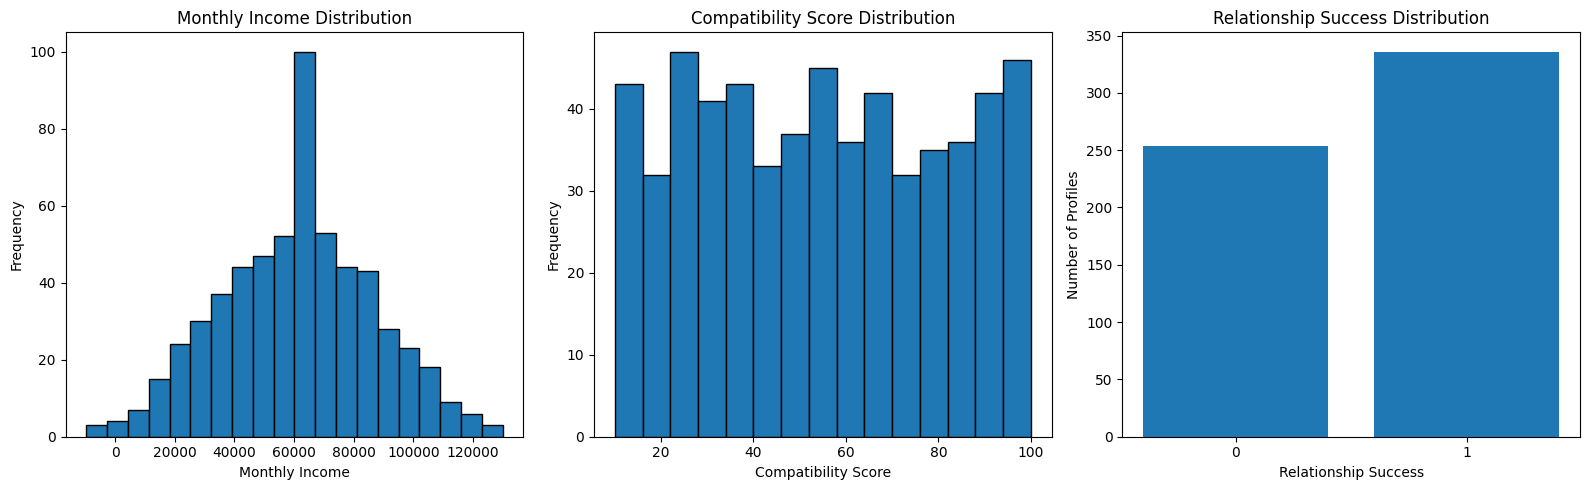

In [17]:
# ============================================================
# UNIVARIATE ANALYSIS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Monthly Income Distribution
axes[0].hist(df["Monthly_Income"], bins=20, edgecolor="black")
axes[0].set_title("Monthly Income Distribution")
axes[0].set_xlabel("Monthly Income")
axes[0].set_ylabel("Frequency")

# Compatibility Score Distribution
axes[1].hist(df["Compatibility_Score"], bins=15, edgecolor="black")
axes[1].set_title("Compatibility Score Distribution")
axes[1].set_xlabel("Compatibility Score")
axes[1].set_ylabel("Frequency")

# Relationship Success Distribution
success_counts = df["Relationship_Success"].value_counts().sort_index()

axes[2].bar(
    success_counts.index.astype(str),
    success_counts.values
)
axes[2].set_title("Relationship Success Distribution")
axes[2].set_xlabel("Relationship Success")
axes[2].set_ylabel("Number of Profiles")

plt.tight_layout()
plt.show()

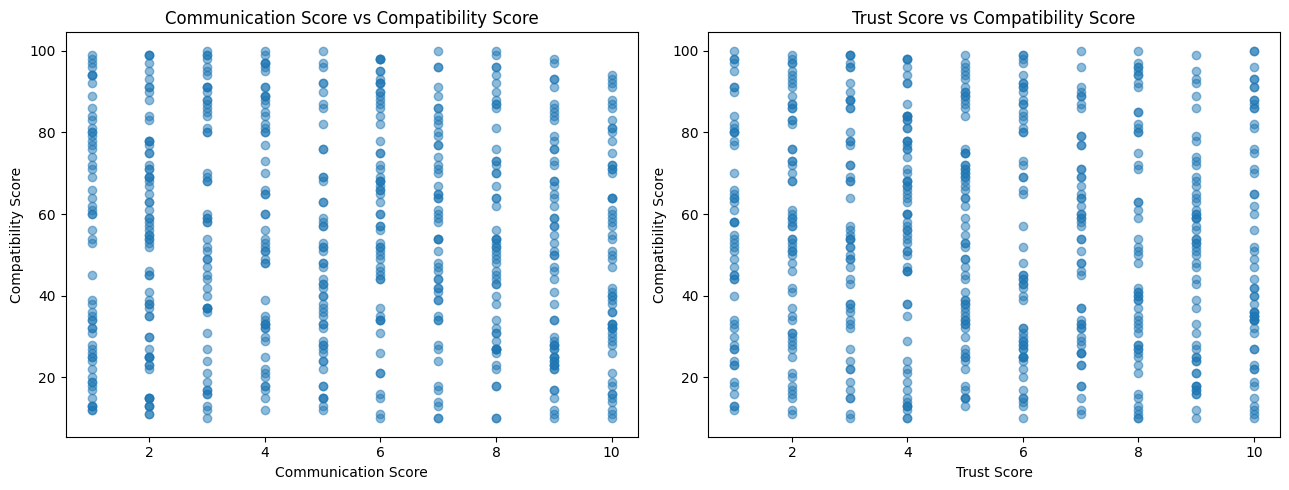

In [18]:
# ============================================================
# BIVARIATE ANALYSIS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Communication Score vs Compatibility Score
axes[0].scatter(
    df["Communication_Score"],
    df["Compatibility_Score"],
    alpha=0.5
)

axes[0].set_title(
    "Communication Score vs Compatibility Score"
)
axes[0].set_xlabel("Communication Score")
axes[0].set_ylabel("Compatibility Score")


# Trust Score vs Compatibility Score
axes[1].scatter(
    df["Trust_Score"],
    df["Compatibility_Score"],
    alpha=0.5
)

axes[1].set_title(
    "Trust Score vs Compatibility Score"
)
axes[1].set_xlabel("Trust Score")
axes[1].set_ylabel("Compatibility Score")

plt.tight_layout()
plt.show()

# Module 2: Feature Engineering, Encoding, and Scaling

In this module, new relationship-based features are engineered, categorical variables are converted into machine-readable numerical features using One-Hot Encoding, and numerical variables are standardized using Z-Score Standardization.


In [19]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

df["Relationship_Quality_Index"] = (
    df["Communication_Score"]
    + df["Trust_Score"]
    + df["Shared_Interests"]
    - df["Red_Flags"]
)

print("New Feature Created: Relationship_Quality_Index")

display(
    df[
        [
            "Communication_Score",
            "Trust_Score",
            "Shared_Interests",
            "Red_Flags",
            "Relationship_Quality_Index"
        ]
    ].head()
)

New Feature Created: Relationship_Quality_Index


,Communication_Score,Trust_Score,Shared_Interests,Red_Flags,Relationship_Quality_Index
0,1,10,2,3.0,10.0
1,10,7,3,0.0,20.0
2,3,4,7,0.0,14.0
3,2,8,6,3.0,13.0
4,2,5,8,2.0,13.0


In [20]:
# ============================================================
# SEPARATE FEATURES AND TARGET VARIABLES
# ============================================================

X = df.drop(
    columns=[
        "Relationship_Success",
        "Compatibility_Score"
    ]
)

y_classification = df["Relationship_Success"]
y_regression = df["Compatibility_Score"]

print("Feature Dataset Shape:", X.shape)
print("Classification Target Shape:", y_classification.shape)
print("Regression Target Shape:", y_regression.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Feature Dataset Shape: (590, 9)
Classification Target Shape: (590,)
Regression Target Shape: (590,)

Feature Columns:
['Age', 'Monthly_Income', 'Communication_Score', 'Trust_Score', 'Shared_Interests', 'Red_Flags', 'Relationship_Duration_Months', 'Zodiac_Sign', 'Relationship_Quality_Index']


In [21]:
# ============================================================
# IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Monthly_Income', 'Communication_Score', 'Trust_Score', 'Shared_Interests', 'Red_Flags', 'Relationship_Duration_Months', 'Relationship_Quality_Index']

Categorical Features:
['Zodiac_Sign']


In [22]:
# ============================================================
# ONE-HOT ENCODING + STANDARDIZATION
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

X_processed = preprocessor.fit_transform(X)

print("Original Feature Shape:", X.shape)
print("Processed Feature Shape:", X_processed.shape)

Original Feature Shape: (590, 9)
Processed Feature Shape: (590, 20)


In [23]:
# ============================================================
# CREATE PROCESSED DATAFRAME
# ============================================================

encoded_categorical_features = (
    preprocessor
    .named_transformers_["cat"]
    .get_feature_names_out(categorical_features)
)

all_feature_names = (
    numerical_features
    + list(encoded_categorical_features)
)

X_processed_df = pd.DataFrame(
    X_processed,
    columns=all_feature_names,
    index=X.index
)

print("Processed Dataset Shape:", X_processed_df.shape)

display(X_processed_df.head())

Processed Dataset Shape: (590, 20)


,Age,Monthly_Income,Communication_Score,Trust_Score,Shared_Interests,Red_Flags,Relationship_Duration_Months,Relationship_Quality_Index,Zodiac_Sign_Aquarius,Zodiac_Sign_Aries,Zodiac_Sign_Cancer,Zodiac_Sign_Capricorn,Zodiac_Sign_Gemini,Zodiac_Sign_Leo,Zodiac_Sign_Libra,Zodiac_Sign_Pisces,Zodiac_Sign_Sagittarius,Zodiac_Sign_Scorpio,Zodiac_Sign_Taurus,Zodiac_Sign_Virgo
0,-0.911914,0.903287,-1.525431,1.612128,-1.180482,0.290582,1.363653,-0.705740,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.600385,1.462282,1.555604,0.547004,-0.824406,-1.501507,0.009468,1.192968,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.018731,0.288844,-0.840757,-0.518119,0.599897,-1.501507,0.630136,0.053743,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.446591,0.857929,-1.183094,0.902045,0.243821,0.290582,-1.175444,-0.136128,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-0.795583,0.033980,-1.183094,-0.163078,0.955973,-0.306781,0.065892,-0.136128,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Module 3: Feature Selection and Cross-Validation

This module applies Recursive Feature Elimination (RFE) to identify the most relevant features for predicting Relationship Success. Stratified K-Fold Cross-Validation is then used to preserve the class distribution across folds and obtain a more reliable estimate of model performance.


In [24]:
# ============================================================
# RECURSIVE FEATURE ELIMINATION (RFE)
# ============================================================

rfe_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Select the 10 most important features
rfe = RFE(
    estimator=rfe_model,
    n_features_to_select=10
)

rfe.fit(X_processed_df, y_classification)

selected_features = X_processed_df.columns[rfe.support_].tolist()

print("Number of Selected Features:", len(selected_features))

print("\nSelected Features:")
for feature in selected_features:
    print("-", feature)

Number of Selected Features: 10

Selected Features:
- Monthly_Income
- Zodiac_Sign_Aquarius
- Zodiac_Sign_Cancer
- Zodiac_Sign_Gemini
- Zodiac_Sign_Leo
- Zodiac_Sign_Libra
- Zodiac_Sign_Pisces
- Zodiac_Sign_Scorpio
- Zodiac_Sign_Taurus
- Zodiac_Sign_Virgo


In [25]:
# ============================================================
# CREATE DATASET USING SELECTED FEATURES
# ============================================================

X_selected = X_processed_df[selected_features]

print("Original Processed Shape:", X_processed_df.shape)
print("Selected Feature Shape:", X_selected.shape)

display(X_selected.head())

Original Processed Shape: (590, 20)
Selected Feature Shape: (590, 10)


,Monthly_Income,Zodiac_Sign_Aquarius,Zodiac_Sign_Cancer,Zodiac_Sign_Gemini,Zodiac_Sign_Leo,Zodiac_Sign_Libra,Zodiac_Sign_Pisces,Zodiac_Sign_Scorpio,Zodiac_Sign_Taurus,Zodiac_Sign_Virgo
0,0.903287,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,1.462282,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.288844,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.857929,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.033980,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
# ============================================================
# STRATIFIED K-FOLD CROSS-VALIDATION
# ============================================================

stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    LogisticRegression(max_iter=1000),
    X_selected,
    y_classification,
    cv=stratified_kfold,
    scoring="accuracy"
)

print("Accuracy for Each Fold:")
print(np.round(cv_scores, 4))

print("\nMean CV Accuracy:",
      round(cv_scores.mean(), 4))

print("Standard Deviation:",
      round(cv_scores.std(), 4))

Accuracy for Each Fold:
[0.5763 0.5339 0.5254 0.6017 0.5424]

Mean CV Accuracy: 0.5559
Standard Deviation: 0.0287


# Module 4: Model Tuning and Evaluation

In this module, the dataset is divided into training and testing sets. Logistic Regression, Decision Tree, and K-Nearest Neighbors (KNN) are evaluated as baseline classification models. Hyperparameter tuning is performed using RandomizedSearchCV

In [27]:
# ============================================================
# TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (472, 10)
Testing Features Shape: (118, 10)
Training Target Shape: (472,)
Testing Target Shape: (118,)


In [28]:
# ============================================================
# BASELINE CLASSIFICATION MODELS
# ============================================================

baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier()
}

baseline_results = {}

for name, model in baseline_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    baseline_results[name] = accuracy

    print(f"{name} Accuracy: {accuracy:.4f}")

Logistic Regression Accuracy: 0.5593
Decision Tree Accuracy: 0.5932
KNN Accuracy: 0.5847


In [29]:
# ============================================================
# HYPERPARAMETER TUNING USING RANDOMIZEDSEARCHCV
# ============================================================

dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 3, 5, 7, 10, 15],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 6],
    "max_features": [None, "sqrt", "log2"]
}

dt_random_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=dt_param_grid,
    n_iter=20,
    scoring="accuracy",
    cv=stratified_kfold,
    random_state=42,
    n_jobs=-1
)

dt_random_search.fit(X_train, y_train)

print("Best Parameters:")
print(dt_random_search.best_params_)

print("\nBest Cross-Validation Accuracy:",
      round(dt_random_search.best_score_, 4))

Best Parameters:
{'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 3, 'criterion': 'entropy'}

Best Cross-Validation Accuracy: 0.5572


In [30]:
# ============================================================
# EVALUATE TUNED DECISION TREE
# ============================================================

best_dt_model = dt_random_search.best_estimator_

dt_tuned_predictions = best_dt_model.predict(X_test)

dt_tuned_accuracy = accuracy_score(
    y_test,
    dt_tuned_predictions
)

print("Baseline Decision Tree Accuracy:",
      round(baseline_results["Decision Tree"], 4))

print("Tuned Decision Tree Accuracy:",
      round(dt_tuned_accuracy, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        dt_tuned_predictions
    )
)

Baseline Decision Tree Accuracy: 0.5932
Tuned Decision Tree Accuracy: 0.5254

Classification Report:
              precision    recall  f1-score   support

           0       0.41      0.22      0.28        51
           1       0.56      0.76      0.65        67

    accuracy                           0.53       118
   macro avg       0.48      0.49      0.46       118
weighted avg       0.49      0.53      0.49       118



# Module 5: Ensemble Models and Final Model Comparison

In this module, Random Forest and AdaBoost ensemble classifiers are trained and evaluated using Stratified K-Fold Cross-Validation. Their performance is compared with the baseline models to identify the most suitable model for predicting Relationship Success.

In [31]:
# ============================================================
# ENSEMBLE MODELS - RANDOM FOREST AND ADABOOST
# ============================================================

ensemble_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    )
}

ensemble_cv_results = {}

for name, model in ensemble_models.items():

    scores = cross_val_score(
        model,
        X_selected,
        y_classification,
        cv=stratified_kfold,
        scoring="accuracy"
    )

    ensemble_cv_results[name] = scores.mean()

    print(f"{name}")
    print("Fold Accuracies:", np.round(scores, 4))
    print("Mean CV Accuracy:", round(scores.mean(), 4))
    print("-" * 50)

Random Forest
Fold Accuracies: [0.4492 0.5254 0.4746 0.5169 0.4915]
Mean CV Accuracy: 0.4915
--------------------------------------------------
AdaBoost
Fold Accuracies: [0.6186 0.5424 0.5763 0.5424 0.5424]
Mean CV Accuracy: 0.5644
--------------------------------------------------


In [32]:
# ============================================================
# ENSEMBLE MODEL TEST ACCURACY
# ============================================================

ensemble_test_results = {}

for name, model in ensemble_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    ensemble_test_results[name] = accuracy

    print(f"{name} Test Accuracy: {accuracy:.4f}")

Random Forest Test Accuracy: 0.5339
AdaBoost Test Accuracy: 0.5847


In [33]:
# ============================================================
# FINAL CLASSIFICATION MODEL COMPARISON
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Tuned Decision Tree",
        "Random Forest",
        "AdaBoost"
    ],

    "Test Accuracy": [
        baseline_results["Logistic Regression"],
        baseline_results["Decision Tree"],
        baseline_results["KNN"],
        dt_tuned_accuracy,
        ensemble_test_results["Random Forest"],
        ensemble_test_results["AdaBoost"]
    ]
})

model_comparison["Accuracy (%)"] = (
    model_comparison["Test Accuracy"] * 100
).round(2)

model_comparison = model_comparison.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

print("Final Classification Model Comparison:")
display(model_comparison)

Final Classification Model Comparison:


,Model,Test Accuracy,Accuracy (%)
0,Decision Tree,0.593220,59.32
1,KNN,0.584746,58.47
2,AdaBoost,0.584746,58.47
3,Logistic Regression,0.559322,55.93
4,Random Forest,0.533898,53.39
5,Tuned Decision Tree,0.525424,52.54


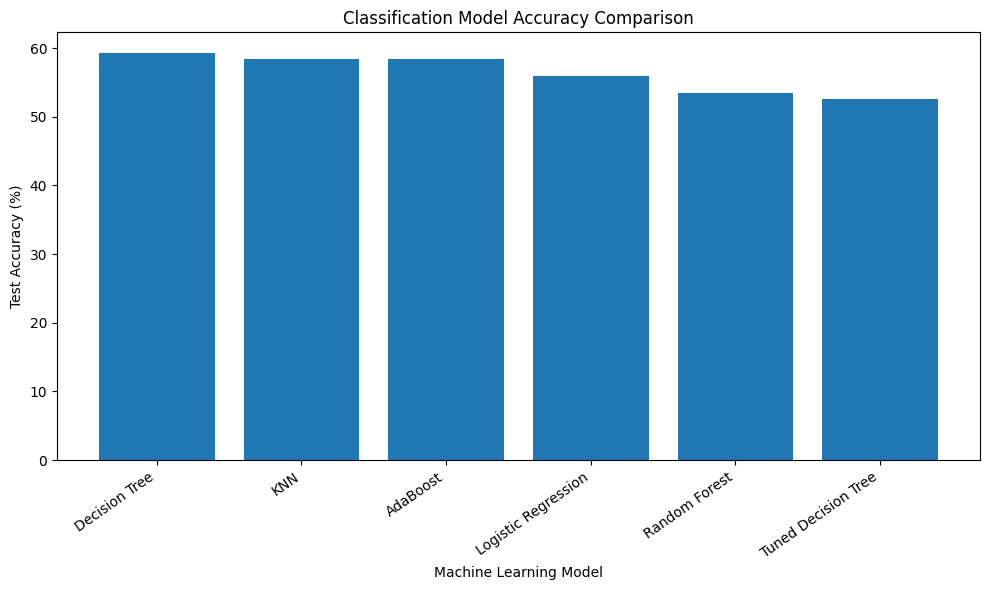

In [34]:
# ============================================================
# MODEL ACCURACY COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    model_comparison["Model"],
    model_comparison["Accuracy (%)"]
)

plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Test Accuracy (%)")

plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# BEST MODEL BASED ON TEST ACCURACY
# ============================================================

best_model_row = model_comparison.iloc[0]

print("Best Model Based on Test Accuracy:")
print(best_model_row["Model"])

print(
    "Accuracy:",
    str(best_model_row["Accuracy (%)"]) + "%"
)

Best Model Based on Test Accuracy:
Decision Tree
Accuracy: 59.32%


# Regression Analysis: Compatibility Score Prediction

The second objective of Project Cupid is to predict the Compatibility Score (10–100). Regression models are trained and evaluated using MAE, RMSE, and R² Score.

In [37]:
# ============================================================
# REGRESSION TRAIN-TEST SPLIT
# ============================================================

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_processed_df,
    y_regression,
    test_size=0.20,
    random_state=42
)

print("Regression Training Features:", X_reg_train.shape)
print("Regression Testing Features:", X_reg_test.shape)

print("Regression Training Target:", y_reg_train.shape)
print("Regression Testing Target:", y_reg_test.shape)

Regression Training Features: (472, 20)
Regression Testing Features: (118, 20)
Regression Training Target: (472,)
Regression Testing Target: (118,)


In [38]:
# ============================================================
# LINEAR REGRESSION
# ============================================================

linear_reg = LinearRegression()

linear_reg.fit(X_reg_train, y_reg_train)

linear_predictions = linear_reg.predict(X_reg_test)

linear_mae = mean_absolute_error(
    y_reg_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        linear_predictions
    )
)

linear_r2 = r2_score(
    y_reg_test,
    linear_predictions
)

print("Linear Regression Results")
print("MAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R² Score:", round(linear_r2, 4))

Linear Regression Results
MAE: 22.611
RMSE: 26.6585
R² Score: -0.055


In [39]:
# ============================================================
# RANDOM FOREST REGRESSION
# ============================================================

rf_reg = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_reg.fit(X_reg_train, y_reg_train)

rf_predictions = rf_reg.predict(X_reg_test)

rf_mae = mean_absolute_error(
    y_reg_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_reg_test,
    rf_predictions
)

print("Random Forest Regression Results")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R² Score:", round(rf_r2, 4))

Random Forest Regression Results
MAE: 23.0636
RMSE: 27.3996
R² Score: -0.1145


In [40]:
# ============================================================
# REGRESSION MODEL COMPARISON
# ============================================================

regression_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],

    "MAE": [
        linear_mae,
        rf_mae
    ],

    "RMSE": [
        linear_rmse,
        rf_rmse
    ],

    "R2 Score": [
        linear_r2,
        rf_r2
    ]
})

regression_comparison = regression_comparison.round(4)

print("Regression Model Comparison:")
display(regression_comparison)

Regression Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,22.6110,26.6585,-0.0550
1,Random Forest Regression,23.0636,27.3996,-0.1145


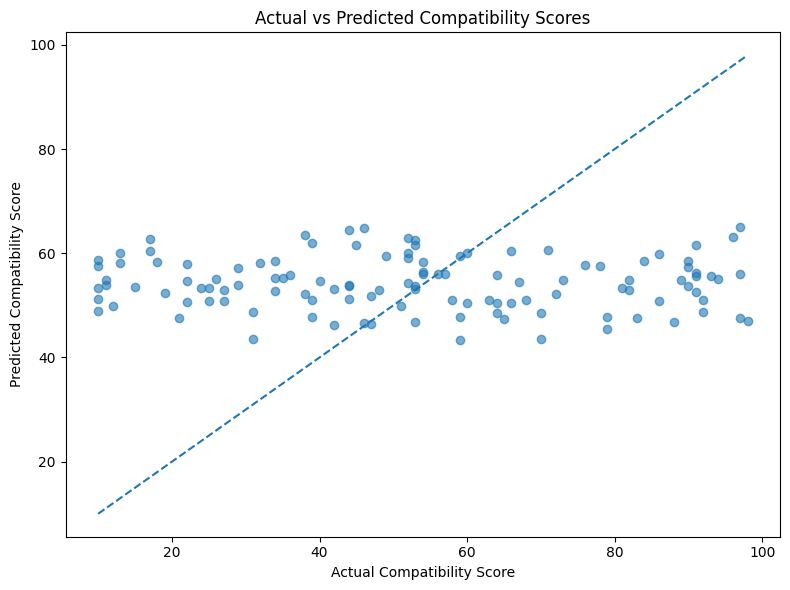

In [41]:
# ============================================================
# ACTUAL VS PREDICTED COMPATIBILITY SCORE
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_test,
    linear_predictions,
    alpha=0.6
)

minimum = min(
    y_reg_test.min(),
    linear_predictions.min()
)

maximum = max(
    y_reg_test.max(),
    linear_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title(
    "Actual vs Predicted Compatibility Scores"
)
plt.xlabel("Actual Compatibility Score")
plt.ylabel("Predicted Compatibility Score")

plt.tight_layout()
plt.show()

In [42]:
# ============================================================
# FINAL REGRESSION RESULT
# ============================================================

print("Best Regression Model: Linear Regression")
print("MAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R² Score:", round(linear_r2, 4))

print(
    "\nObservation: The negative R² score indicates that "
    "the available features have limited predictive power "
    "for Compatibility Score in the current synthetic dataset."
)

Best Regression Model: Linear Regression
MAE: 22.611
RMSE: 26.6585
R² Score: -0.055

Observation: The negative R² score indicates that the available features have limited predictive power for Compatibility Score in the current synthetic dataset.


# Final Conclusion

Project Cupid successfully implemented an end-to-end machine learning workflow for relationship compatibility and longevity analysis.

## Classification – Relationship Success

Multiple classification algorithms were evaluated for predicting Relationship Success.

- Logistic Regression Test Accuracy: 55.93%
- Decision Tree Test Accuracy: 59.32%
- KNN Test Accuracy: 58.47%
- Tuned Decision Tree Test Accuracy: 52.54%
- Random Forest Test Accuracy: 53.39%
- AdaBoost Test Accuracy: 58.47%

Among the evaluated models, the baseline Decision Tree achieved the highest test accuracy of 59.32%. However, AdaBoost showed comparatively stronger cross-validation performance with a mean CV accuracy of 56.44%, suggesting more stable performance across different folds.

Hyperparameter tuning using RandomizedSearchCV did not improve the Decision Tree's test performance. This demonstrates that hyperparameter tuning does not always guarantee better performance on unseen data.

## Regression – Compatibility Score

Two regression models were evaluated for predicting Compatibility Score:

- Linear Regression: MAE = 22.6110, RMSE = 26.6585, R² = -0.0550
- Random Forest Regression: MAE = 23.0636, RMSE = 27.3996, R² = -0.1145

Linear Regression performed better than Random Forest Regression based on lower MAE and